<div style="border-left:4px solid #3D6FB0;padding:6px 0 8px 16px;"><div style="opacity:.72;font-size:12px;letter-spacing:1.4px;">DATOS MASIVOS II · PRÁCTICA</div><div style="color:#3D6FB0;font-size:27px;font-weight:700;margin-top:4px;">Carga y exploración del dump de Wikipedia en inglés</div><div style="opacity:.72;font-size:14px;margin-top:6px;">Lectura en paralelo del dump multistream, análisis descriptivo y construcción del grafo de enlaces entre artículos.</div><div style="opacity:.72;font-size:14px;margin-top:6px;margin-bottom:10px;">Equipo Tres: Castrillo Cruz Karen Arlet, Ramos González Nadia, Zamora Antiga Ángel Javier.</div><img src="https://mmss.iimas.unam.mx/dmmss/wp-content/uploads/2026/02/cropped-LogoUNAM_IIMAS_Negro50-scaled-2.png" width="200"/></div>

### Objetivo

Este notebook documenta el contenido del archivo **`enwiki-latest-pages-articles-multistream.xml.bz2`** y lo carga
**completo** para construir el **grafo de enlaces entre artículos**. Sobre ese grafo, `02_pagerank_hits.ipynb` calcula
**PageRank** y **HITS**, y `03_topic_sensitive.ipynb` el **PageRank sensible a tópico**.

**¿Qué es este archivo?** La Fundación Wikimedia publica periódicamente *dumps* de cada Wikipedia. El dump
`pages-articles` contiene **la última revisión** de cada página de contenido (artículos, redirecciones, plantillas,
categorías, páginas de ayuda, módulos, etc.). No contiene el historial de ediciones ni las páginas de usuario o de
discusión. El contenido viene en formato XML de exportación de MediaWiki, y el texto de cada página en
*wikitexto*.

**¿Qué significa *multistream*?** En lugar de un único stream bz2, el archivo es una **concatenación de muchos
streams bz2 independientes**, cada uno con 100 páginas. Lo acompaña un **índice**
(`enwiki-latest-pages-articles-multistream-index.txt.bz2`) con el byte en que empieza cada stream. Gracias a eso:

* se puede **leer un artículo concreto** descomprimiendo solo su stream (acceso aleatorio), y
* se puede **procesar el archivo en paralelo**, repartiendo rangos de streams entre varios procesos.

### Contenido

1. Configuración del entorno
2. Inspección del archivo: cabecera, `<siteinfo>`, namespaces y esquema de `<page>`
3. Estructura multistream e índice, con acceso aleatorio
4. Extracción completa en paralelo a Parquet
5. Carga en PySpark
6. Análisis descriptivo del dataset completo
7. Construcción del grafo de enlaces
8. Cómo usar el grafo para PageRank / HITS / Topic-Sensitive PageRank
9. Conclusiones y limitaciones

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · ENTORNO</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">1. Configuración del entorno</span></div>



El dump pesa ~27 GB comprimido y ~110 GB descomprimido, así que **nunca se descomprime a disco**: todo se lee en
streaming. Las rutinas de lectura y extracción están en el módulo [`wiki_extract.py`](../wiki_extract.py). Están en un
archivo aparte porque en Windows `multiprocessing` lanza los procesos con *spawn*, y las funciones de trabajo tienen
que poder importarse.

PySpark 4.1 necesita **Java 17+**. En Windows además necesita los binarios nativos de Hadoop (`winutils.exe` y
`hadoop.dll`) en `%HADOOP_HOME%\bin` para leer y escribir archivos locales.

In [1]:
import os, sys, glob, json, time, bz2, html
from pathlib import Path
import xml.etree.ElementTree as ET

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

sys.path.insert(0, "..")   # wiki_extract.py está en la carpeta Wikipedia/
import wiki_extract as we

DATA = Path("..") / "data"
RUTA_XML = DATA / "enwiki-latest-pages-articles-multistream.xml.bz2"
RUTA_IDX = DATA / "enwiki-latest-pages-articles-multistream-index.txt.bz2"
GRAFO = DATA / "grafo"

# Java y Hadoop para PySpark
if "JAVA_HOME" not in os.environ:
    jdks = sorted(glob.glob(r"C:\Program Files\Eclipse Adoptium\jdk-17*"))
    if jdks:
        os.environ["JAVA_HOME"] = jdks[-1]
os.environ.setdefault("HADOOP_HOME", r"C:\hadoop")
os.environ["PATH"] = str(Path(os.environ["HADOOP_HOME"]) / "bin") + os.pathsep + os.environ["PATH"]
os.environ["PYSPARK_PYTHON"] = sys.executable

pd.set_option("display.max_colwidth", 80)
pd.set_option("display.float_format", "{:,.2f}".format)

# Paleta única del repositorio: azul principal, rojo de acento y grises neutros
AZUL, ROJO = "#3D6FB0", "#B03D3D"
GRIS, GRIS_CLARO, TINTA = "#8C8C8C", "#EEF1F6", "#333333"
plt.rcParams.update({
    "figure.dpi": 100, "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.edgecolor": "#999999", "axes.labelcolor": TINTA,
    "xtick.color": TINTA, "ytick.color": TINTA, "legend.frameon": False,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#DDDDDD", "grid.linewidth": 0.6, "axes.axisbelow": True,
})

print("JAVA_HOME  :", os.environ.get("JAVA_HOME"))
print("HADOOP_HOME:", os.environ.get("HADOOP_HOME"), "| winutils:", (Path(os.environ["HADOOP_HOME"]) / "bin" / "winutils.exe").exists())

JAVA_HOME  : C:\Program Files\Eclipse Adoptium\jdk-17.0.20.101-hotspot
HADOOP_HOME: C:\hadoop | winutils: True


<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · DATOS</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">2. Inspección del archivo</span></div>



### 2.1 Metadatos y firma bz2

In [2]:
for ruta in (RUTA_XML, RUTA_IDX):
    with open(ruta, "rb") as f:
        firma = f.read(10)
    print(f"{ruta.name}\n  tamaño: {ruta.stat().st_size / 1e9:,.2f} GB   firma: {firma!r}")

enwiki-latest-pages-articles-multistream.xml.bz2
  tamaño: 26.92 GB   firma: b'BZh91AY&SY'
enwiki-latest-pages-articles-multistream-index.txt.bz2
  tamaño: 0.29 GB   firma: b'BZh91AY&SY'


Los primeros bytes `BZh9` son la cabecera de un stream bz2 (con bloques de 900 kB), y `1AY&SY` (`0x314159265359`, los
dígitos de π) es la marca de inicio de bloque. Cada uno de los streams del archivo empieza con esa firma.

### 2.2 Vista cruda del XML

Se descomprimen en streaming solo los primeros caracteres:

In [3]:
with bz2.open(RUTA_XML, "rt", encoding="utf-8") as f:
    inicio = f.read(4200)
print(inicio)

<mediawiki xmlns="http://www.mediawiki.org/xml/export-0.11/" xmlns:xsi="http://www.w3.org/2001/XMLSchema-instance" xsi:schemaLocation="http://www.mediawiki.org/xml/export-0.11/ http://www.mediawiki.org/xml/export-0.11.xsd" version="0.11" xml:lang="en">
  <siteinfo>
    <sitename>Wikipedia</sitename>
    <dbname>enwiki</dbname>
    <base>https://en.wikipedia.org/wiki/Main_Page</base>
    <generator>MediaWiki 1.47.0-wmf.21</generator>
    <case>first-letter</case>
    <namespaces>
      <namespace key="-2" case="first-letter">Media</namespace>
      <namespace key="-1" case="first-letter">Special</namespace>
      <namespace key="0" case="first-letter" />
      <namespace key="1" case="first-letter">Talk</namespace>
      <namespace key="2" case="first-letter">User</namespace>
      <namespace key="3" case="first-letter">User talk</namespace>
      <namespace key="4" case="first-letter">Wikipedia</namespace>
      <namespace key="5" case="first-letter">Wikipedia talk</namespace>
      <n

### 2.3 `<siteinfo>` y namespaces

El primer stream del archivo contiene solo la etiqueta raíz `<mediawiki>` y el bloque `<siteinfo>`, que describe el
sitio. Su longitud es el primer offset del índice.

In [4]:
with bz2.open(RUTA_IDX, "rt", encoding="utf-8") as f:
    primer_offset = int(f.readline().split(":", 1)[0])

cabecera = we.leer_cabecera(RUTA_XML, primer_offset)
NSX = "{http://www.mediawiki.org/xml/export-0.11/}"
raiz = ET.fromstring(cabecera + "</mediawiki>")
si = raiz.find(f"{NSX}siteinfo")

print("Primer offset (bytes del stream de cabecera):", primer_offset)
print("Versión del esquema de exportación:", raiz.get("version"), "| idioma:", raiz.get(f"{{http://www.w3.org/XML/1998/namespace}}lang"))
for campo in ("sitename", "dbname", "base", "generator", "case"):
    print(f"  {campo:10s}: {si.findtext(NSX + campo)}")

namespaces = pd.DataFrame(
    [(int(n.get("key")), n.text or "(artículos)", n.get("case")) for n in si.find(f"{NSX}namespaces")],
    columns=["ns", "nombre", "case"],
)
NS_NOMBRE = dict(zip(namespaces.ns, namespaces.nombre))
namespaces

Primer offset (bytes del stream de cabecera): 570
Versión del esquema de exportación: 0.11 | idioma: en
  sitename  : Wikipedia
  dbname    : enwiki
  base      : https://en.wikipedia.org/wiki/Main_Page
  generator : MediaWiki 1.47.0-wmf.21
  case      : first-letter


,ns,nombre,case
0,-2,Media,first-letter
1,-1,Special,first-letter
2,0,(artículos),first-letter
3,1,Talk,first-letter
4,2,User,first-letter
5,3,User talk,first-letter
6,4,Wikipedia,first-letter
7,5,Wikipedia talk,first-letter
8,6,File,first-letter
9,7,File talk,first-letter


El *namespace* (`ns`) clasifica cada página. Los artículos enciclopédicos están en **ns = 0**, que no tiene prefijo.
Los demás llevan un prefijo en el título (`Category:`, `Template:`, `File:`…). Los namespaces impares son de
discusión (*talk*). Según la documentación de Wikimedia, el dump *pages-articles* no los incluye. La tabla de la
sección 6.1, que cuenta todas las páginas extraídas, lo confirma: solo aparecen namespaces pares. Las 30 entradas
de `<siteinfo>` son los namespaces que existen en el sitio, no los que trae el archivo.

### 2.4 Esquema de una página

Cada página es un elemento `<page>` con una sola `<revision>` (la más reciente). Por ejemplo, la primera página del
dump es una **redirección**:

In [5]:
print(we.leer_articulo(RUTA_XML, primer_offset, "AccessibleComputing"))

<page>
    <title>AccessibleComputing</title>
    <ns>0</ns>
    <id>10</id>
    <redirect title="Computer accessibility" />
    <revision>
      <id>1367012995</id>
      <parentid>1362980932</parentid>
      <timestamp>2026-07-31T12:02:55Z</timestamp>
      <contributor>
        <username>Graham87</username>
        <id>194203</id>
      </contributor>
      <minor />
      <comment>1 revision imported: import old edit from [[nost:AccessibleComputing]]</comment>
      <origin>1362980932</origin>
      <model>wikitext</model>
      <format>text/x-wiki</format>
      <text bytes="111" sha1="kmysdltgexdwkv2xsml3j44jb56dxvn" xml:space="preserve">#REDIRECT [[Computer accessibility]]

{{rcat shell|
{{R from move}}
{{R from CamelCase}}
{{R unprintworthy}}
}}</text>
      <sha1>kmysdltgexdwkv2xsml3j44jb56dxvn</sha1>
    </revision>
</page>


| Elemento / atributo | Significado | Ejemplo |
|---|---|---|
| `page/title` | Título canónico (con prefijo de namespace si no es ns 0) | `Anarchism` |
| `page/ns` | Namespace (ver tabla anterior) | `0` |
| `page/id` | Identificador único de página | `12` |
| `page/redirect@title` | Solo en redirecciones: título de destino | `Computer accessibility` |
| `revision/id` | Identificador de la revisión vigente | `1378247183` |
| `revision/parentid` | Revisión anterior | `1375097780` |
| `revision/timestamp` | Fecha de la última edición (UTC, ISO 8601) | `2026-10-03T17:40:24Z` |
| `revision/contributor/username`, `/id` | Usuario registrado que hizo la última edición | `Inzessin`, `52005691` |
| `revision/contributor/ip` | En lugar de usuario, si la edición fue anónima | `192.0.2.1` |
| `revision/minor` | Presente si la edición se marcó como menor | `<minor />` |
| `revision/comment` | Resumen de edición | `organized→organised, BrE` |
| `revision/origin` | Revisión de origen del contenido | `1378247183` |
| `revision/model`, `/format` | Modelo de contenido (`wikitext`, `Scribunto`, `css`, `javascript`, `json`…) y formato MIME | `wikitext`, `text/x-wiki` |
| `revision/text` | Contenido en wikitexto; `@bytes` = tamaño en bytes, `@sha1` = hash | `{{Short description|…}} '''Anarchism''' is…` |
| `revision/sha1` | Hash SHA-1 (base 36) del contenido | `h9ttsnygxrv29rs1jmn0mw2vhkpyrzr` |

Dentro del wikitexto, los elementos que importan para el grafo son:

* `[[Destino]]` o `[[Destino|texto visible]]` → **enlace interno** a otro artículo (lo que forma las aristas).
* `[[Category:Nombre]]` → la página pertenece a esa **categoría**.
* `{{Plantilla|…}}` → inclusión de plantillas (infoboxes, navboxes, referencias…).
* `<ref>…</ref>` → referencias bibliográficas.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · DATOS</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">3. Estructura multistream e índice</span></div>

Cada línea del índice tiene el formato `offset:page_id:título`. Las 100 páginas de un mismo stream comparten offset.
Se recorre el índice completo una sola vez (~1 min) para obtener los offsets de todos los streams y, de paso, la
posición de algunos artículos para la demo de acceso aleatorio.

In [6]:
with bz2.open(RUTA_IDX, "rt", encoding="utf-8") as f:
    for _ in range(5):
        print(f.readline().rstrip())

t0 = time.time()
DEMO = ["PageRank", "Mexico", "Anarchism", "National Autonomous University of Mexico"]
offsets, n_paginas_idx, encontrados = we.leer_indice(RUTA_IDX, DEMO)
print(f"\nÍndice leído en {time.time() - t0:.0f} s")
print(f"Páginas en el índice : {n_paginas_idx:,}")
print(f"Streams bz2          : {len(offsets):,}   (≈ {n_paginas_idx / len(offsets):.1f} páginas por stream)")
print(f"Último offset        : {offsets[-1]:,} de {RUTA_XML.stat().st_size:,} bytes")

570:10:AccessibleComputing
570:12:Anarchism
570:13:AfghanistanHistory
570:14:AfghanistanGeography
570:15:AfghanistanPeople



Índice leído en 49 s
Páginas en el índice : 25,932,219
Streams bz2          : 259,358   (≈ 100.0 páginas por stream)
Último offset        : 26,917,192,226 de 26,917,225,724 bytes


count   259,358.00
mean        101.35
std          77.33
min           0.46
50%          88.53
90%         159.62
99%         370.73
max       5,413.25


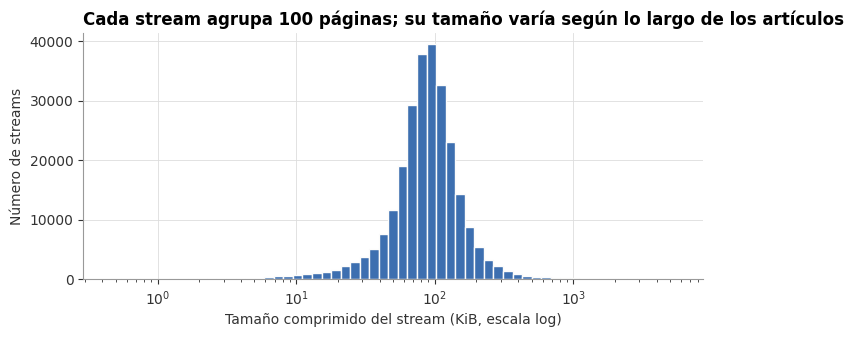

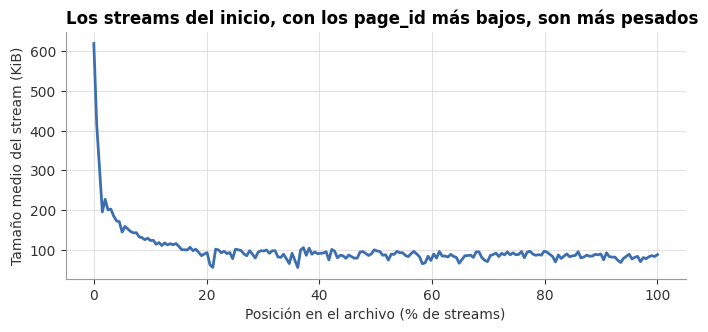

In [7]:
tam_streams = np.diff(np.append(offsets, RUTA_XML.stat().st_size))
print(pd.Series(tam_streams / 1024, name="tamaño comprimido por stream (KiB)").describe(percentiles=[.5, .9, .99]).to_string())

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(tam_streams / 1024, bins=np.logspace(np.log10(tam_streams.min() / 1024), np.log10(tam_streams.max() / 1024), 60),
        color=AZUL, edgecolor="#fcfcfb", linewidth=1)
ax.set_xscale("log")
ax.set_xlabel("Tamaño comprimido del stream (KiB, escala log)")
ax.set_ylabel("Número de streams")
ax.set_title("Cada stream agrupa 100 páginas; su tamaño varía según lo largo de los artículos", loc="left")
plt.show()

# Tamaño del stream a lo largo del archivo, que está ordenado por page_id creciente
fig, ax = plt.subplots(figsize=(8, 3.2))
bloques = np.array_split(tam_streams, 200)
ax.plot(np.linspace(0, 100, len(bloques)), [b.mean() / 1024 for b in bloques], color=AZUL, linewidth=2)
ax.set_xlabel("Posición en el archivo (% de streams)")
ax.set_ylabel("Tamaño medio del stream (KiB)")
ax.set_title("Los streams del inicio, con los page_id más bajos, son más pesados", loc="left")
plt.show()

El archivo está ordenado por `page_id` creciente: la sección 4 lo comprueba en las 25.9 M páginas. MediaWiki asigna
el `page_id` al crear la página, así que un `page_id` bajo **sugiere** una página creada antes. Es solo un proxy: el
dump no trae la fecha de creación (solo la de la última revisión), y las importaciones, restauraciones y fusiones de
historial rompen el orden (*AccessibleComputing* tiene `page_id` 10, pero su revisión vigente es de 2026). Que los
streams del inicio pesen más es compatible con que los artículos más antiguos sean más largos, pero esa
interpretación no se mide aquí.

### 3.1 Acceso aleatorio

Con el offset del índice basta con hacer `seek` a ese byte y descomprimir **un solo stream** (unos cientos de KB) para
recuperar cualquier artículo, sin recorrer los 27 GB:

In [8]:
for titulo, (off, pid) in encontrados.items():
    t0 = time.time()
    xml_pag = we.leer_articulo(RUTA_XML, off, titulo)
    print(f"{titulo!r:45s} page_id={pid:<9} offset={off:>14,}  -> {len(xml_pag):>9,} caracteres en {1000 * (time.time() - t0):.0f} ms")

print("\n" + we.leer_articulo(RUTA_XML, *encontrados["PageRank"][:1], "PageRank")[:2500])

'Anarchism'                                   page_id=12        offset=           570  ->   115,493 caracteres en 93 ms
'National Autonomous University of Mexico'    page_id=145426    offset=   682,063,690  ->   104,400 caracteres en 100 ms
'Mexico'                                      page_id=3966054   offset= 4,464,216,278  ->   271,419 caracteres en 23 ms
'PageRank'                                    page_id=26334893  offset=11,268,858,975  ->    77,930 caracteres en 11 ms

<page>
    <title>PageRank</title>
    <ns>0</ns>
    <id>26334893</id>
    <revision>
      <id>1378661007</id>
      <parentid>1378042705</parentid>
      <timestamp>2026-10-05T14:42:16Z</timestamp>
      <contributor>
        <username>Mindmatrix</username>
        <id>160367</id>
      </contributor>
      <minor />
      <comment>revert - see [[WP:SDFORMAT]]</comment>
      <origin>1378661007</origin>
      <model>wikitext</model>
      <format>text/x-wiki</format>
      <text bytes="74353" sha1="9uc14m1i1sx

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · EXTRACCIÓN</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">4. Extracción completa en paralelo</span></div>

La función `we.extraer_todo` reparte los 259 mil streams en 400 rangos de tamaño similar y los procesa con 14
procesos. Cada proceso:

1. lee su rango de bytes y descomprime stream por stream (`bz2.BZ2Decompressor`),
2. separa cada `<page>…</page>` y lo parsea con `xml.etree.ElementTree`,
3. extrae del wikitexto los **enlaces a artículos** y las **categorías** con una expresión regular. Los destinos se
   normalizan como en MediaWiki: `_` → espacio, primera letra en mayúscula, sin `#sección`. Se descartan los enlaces a
   otros namespaces (`File:`, `Template:`…) y los interwiki (`fr:`, `wikt:`…),
4. escribe tres archivos Parquet (compresión zstd):

| Tabla | Filas | Columnas |
|---|---|---|
| `data/paginas` | todas las páginas | `page_id, title, ns, is_redirect, redirect_target, rev_id, parent_id, timestamp, contributor_user, contributor_id, contributor_ip, minor, model, format, text_bytes, n_enlaces, n_categorias, is_disambig` |
| `data/enlaces` | un enlace distinto por artículo (ns 0, no redirección) | `src_id, dst_title` |
| `data/categorias` | pertenencia a categoría (artículos y páginas de categoría) | `page_id, category` |

El texto completo **no se guarda** (serían ~110 GB). El proceso se puede reanudar: si un rango ya tiene su Parquet, se
omite y se reutilizan sus estadísticas guardadas.

In [9]:
t0 = time.time()
stats = pd.DataFrame(we.extraer_todo(RUTA_XML, offsets, DATA, procesos=14, n_tareas=400))
print(f"Llamada terminada en {time.time() - t0:,.0f} s ({stats.omitido.sum()} de {len(stats)} rangos ya estaban procesados)")

# Tiempo real de la extracción, calculado a partir de las marcas de tiempo de cada tarea
inicio_real = (stats.fin_unix - stats.segundos).min()
duracion = stats.fin_unix.max() - inicio_real
resumen = pd.Series({
    "rangos procesados": len(stats),
    "streams": stats.streams.sum(),
    "páginas": stats.paginas.sum(),
    "enlaces (artículo → título)": stats.enlaces.sum(),
    "pertenencias a categoría": stats.categorias.sum(),
    "GB comprimidos leídos": stats.bytes_comp.sum() / 1e9,
    "GB de XML descomprimido": stats.bytes_xml.sum() / 1e9,
    "duración real (min)": duracion / 60,
    "throughput (MB/s comprimidos)": stats.bytes_comp.sum() / 1e6 / duracion,
    "throughput (MB/s XML)": stats.bytes_xml.sum() / 1e6 / duracion,
})
print(resumen.to_string(float_format="{:,.1f}".format))

extra = stats.streams.sum() - len(offsets)
print(f"\nStreams leídos: {stats.streams.sum():,} = {len(offsets):,} del índice + {extra} sin páginas")
assert stats.paginas.sum() == n_paginas_idx, "El número de páginas no coincide con el índice"

# Orden del archivo: page_id estrictamente creciente en todas las partes, en orden de bytes
ids_archivo = np.concatenate([pd.read_parquet(p, columns=["page_id"]).page_id.to_numpy()
                              for p in sorted((DATA / "paginas").glob("part-*.parquet"))])
assert np.all(np.diff(ids_archivo) > 0)
print(f"✔ page_id estrictamente creciente a lo largo del archivo: de {ids_archivo[0]:,} a {ids_archivo[-1]:,}")
print("✔ Verificación: se extrajeron exactamente las", f"{n_paginas_idx:,}", "páginas del índice")

Llamada terminada en 1,583 s (0 de 400 rangos ya estaban procesados)
rangos procesados                       400.0
streams                             259,360.0
páginas                          25,932,219.0
enlaces (artículo → título)     254,346,209.0
pertenencias a categoría         47,705,914.0
GB comprimidos leídos                    26.9
GB de XML descomprimido                 117.8
duración real (min)                      26.4
throughput (MB/s comprimidos)            17.0
throughput (MB/s XML)                    74.5

Streams leídos: 259,360 = 259,358 del índice + 2 sin páginas


✔ page_id estrictamente creciente a lo largo del archivo: de 10 a 84,442,244
✔ Verificación: se extrajeron exactamente las 25,932,219 páginas del índice


Se leen **2 streams más** de los que lista el índice. El índice solo registra streams que contienen páginas, y hay dos
que no tienen ninguna: un stream bz2 **vacío** de 14 bytes a mitad del archivo (byte 13 421 748 273) y el último, que
solo contiene la etiqueta de cierre `</mediawiki>`. El número de **páginas** coincide exactamente con el índice.

In [10]:
def tam_dir(p):
    return sum(f.stat().st_size for f in Path(p).rglob("*") if f.is_file()) / 1e9

pd.Series({sub: tam_dir(DATA / sub) for sub in ("paginas", "enlaces", "categorias")}, name="GB en disco").to_frame()

,GB en disco
paginas,1.21
enlaces,2.55
categorias,0.49


<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · SPARK</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">5. Carga en PySpark</span></div>

Se crea una sesión local que usa todos los núcleos (`local[*]`). En modo local, el *driver* también ejecuta las
tareas, así que su memoria es la memoria de trabajo de Spark.

In [11]:
from pyspark.sql import SparkSession, functions as F, Window

spark = (
    SparkSession.builder
    .appName("Practica3-Wikipedia")
    .master("local[*]")
    .config("spark.driver.memory", "20g")
    .config("spark.driver.maxResultSize", "4g")
    .config("spark.sql.shuffle.partitions", "400")
    .config("spark.local.dir", str(Path("..").resolve() / "spark_tmp"))
    .config("spark.sql.execution.arrow.pyspark.enabled", "true")
    .config("spark.ui.showConsoleProgress", "false")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")
print("Spark", spark.version, "| núcleos:", spark.sparkContext.defaultParallelism)

Spark 4.1.2 | núcleos: 16


In [12]:
paginas = spark.read.parquet(str(DATA / "paginas"))
enlaces = spark.read.parquet(str(DATA / "enlaces"))
categorias = spark.read.parquet(str(DATA / "categorias"))
for nombre, df in (("paginas", paginas), ("enlaces", enlaces), ("categorias", categorias)):
    df.createOrReplaceTempView(nombre)

paginas.printSchema()
enlaces.printSchema()
categorias.printSchema()

root
 |-- page_id: long (nullable = true)
 |-- title: string (nullable = true)
 |-- ns: integer (nullable = true)
 |-- is_redirect: boolean (nullable = true)
 |-- redirect_target: string (nullable = true)
 |-- rev_id: long (nullable = true)
 |-- parent_id: long (nullable = true)
 |-- timestamp: timestamp (nullable = true)
 |-- contributor_user: string (nullable = true)
 |-- contributor_id: long (nullable = true)
 |-- contributor_ip: string (nullable = true)
 |-- minor: boolean (nullable = true)
 |-- model: string (nullable = true)
 |-- format: string (nullable = true)
 |-- text_bytes: long (nullable = true)
 |-- n_enlaces: integer (nullable = true)
 |-- n_categorias: integer (nullable = true)
 |-- is_disambig: boolean (nullable = true)

root
 |-- src_id: long (nullable = true)
 |-- dst_title: string (nullable = true)

root
 |-- page_id: long (nullable = true)
 |-- category: string (nullable = true)



In [13]:
conteos = {n: spark.table(n).count() for n in ("paginas", "enlaces", "categorias")}
pd.Series(conteos, name="filas").map("{:,}".format).to_frame()

,filas
paginas,"25,932,219"
enlaces,"254,346,209"
categorias,"47,705,914"


In [14]:
paginas.filter("ns = 0").select("page_id", "title", "is_redirect", "redirect_target", "timestamp",
                                "contributor_user", "text_bytes", "n_enlaces", "n_categorias", "is_disambig").show(8, truncate=30)

+--------+------------------+-----------+------------------------------+-------------------+----------------+----------+---------+------------+-----------+
| page_id|             title|is_redirect|               redirect_target|          timestamp|contributor_user|text_bytes|n_enlaces|n_categorias|is_disambig|
+--------+------------------+-----------+------------------------------+-------------------+----------------+----------+---------+------------+-----------+
|16425140|       5679 Akkado|       true|List of minor planets: 5001...|2026-04-16 15:31:06|      Tom.Reding|       313|     NULL|        NULL|      false|
|16425141|           Pareage|       true|                       Paréage|2008-03-20 01:48:35|           Eubot|        58|     NULL|        NULL|      false|
|16425142|       8414 Atsuko|       true|List of minor planets: 8001...|2026-04-16 15:31:08|      Tom.Reding|       315|     NULL|        NULL|      false|
|16425143|              KKPs|       true|               Kappa Ka

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · EXPLORACIÓN</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">6. Análisis descriptivo del dataset completo</span></div>

Las agregaciones se hacen en Spark. Solo los resultados (pocas filas) se pasan a pandas para mostrarlos.

### 6.1 Páginas por namespace y redirecciones

In [15]:
por_ns = spark.sql('''
    SELECT ns, COUNT(*) AS paginas, SUM(CAST(is_redirect AS INT)) AS redirecciones,
           SUM(text_bytes) / 1e9 AS gb_texto
    FROM paginas GROUP BY ns ORDER BY paginas DESC
''').toPandas()
por_ns.insert(1, "nombre", por_ns.ns.map(NS_NOMBRE))
por_ns["% redirección"] = 100 * por_ns.redirecciones / por_ns.paginas
por_ns["% del total"] = 100 * por_ns.paginas / por_ns.paginas.sum()
por_ns

,ns,nombre,paginas,redirecciones,gb_texto,% redirección,% del total
0,0,(artículos),19314502,12065403,71.43,62.47,74.48
1,14,Category,2648210,37,0.43,0.00,10.21
2,4,Wikipedia,1572638,168316,20.79,10.70,6.06
3,6,File,1022983,20295,0.68,1.98,3.94
4,10,Template,903764,190188,1.52,21.04,3.49
5,118,Draft,334269,273382,0.45,81.79,1.29
6,100,Portal,105171,11037,0.16,10.49,0.41
7,828,Module,19626,1926,0.09,9.81,0.08
8,12,Help,2907,1874,0.01,64.47,0.01
9,8,MediaWiki,2810,42,0.01,1.49,0.01


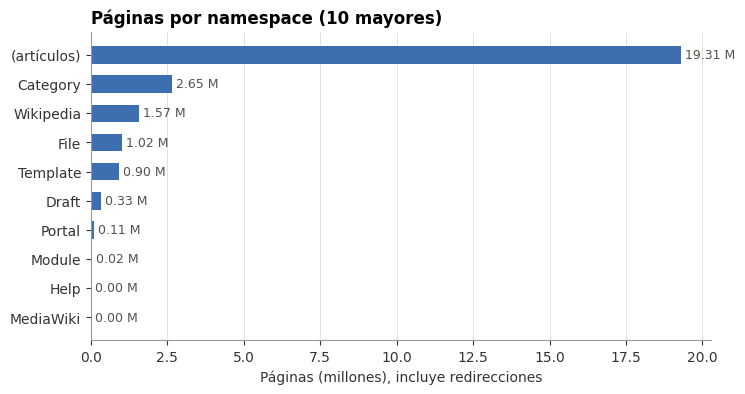

In [16]:
top = por_ns.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(top.nombre, top.paginas / 1e6, color=AZUL, height=0.6)
for y, v in enumerate(top.paginas / 1e6):
    ax.text(v, y, f" {v:,.2f} M", va="center", color="#52514e", fontsize=9)
ax.set_xlabel("Páginas (millones), incluye redirecciones")
ax.set_title("Páginas por namespace (10 mayores)", loc="left")
ax.grid(axis="y", visible=False)
plt.show()

In [17]:
art = paginas.filter("ns = 0")
n0 = art.groupBy("is_redirect").count().toPandas().set_index("is_redirect")["count"]
n_desamb = art.filter("is_disambig").count()
print(f"Namespace 0: {n0.sum():,} páginas")
print(f"  artículos (no redirección): {n0[False]:,}  ({100 * n0[False] / n0.sum():.1f} %)")
print(f"  redirecciones             : {n0[True]:,}  ({100 * n0[True] / n0.sum():.1f} %)")
print(f"  de los artículos, páginas de desambiguación / set index: {n_desamb:,}")

Namespace 0: 19,314,502 páginas
  artículos (no redirección): 7,249,099  (37.5 %)
  redirecciones             : 12,065,403  (62.5 %)
  de los artículos, páginas de desambiguación / set index: 372,263


> **Nota sobre la marca de desambiguación.** Este conteo es el de la primera versión del extractor. Al revisar los
> resultados se encontró que la marca `is_disambig` tenía falsos positivos: aceptaba cualquier plantilla cuyo nombre
> *empezara* o *terminara* como una de desambiguación, así que marcaba artículos normales que llevan
> `{{Disambiguation needed}}`, `{{Set index article}}`, `{{Year dab}}`, `{{Italic disambiguation}}` o `{{Cite DAB}}`
> (p. ej. *Irish Republican Army*, *Meta-analysis*, *2011*, *Detroit Free Press*). La expresión `RE_DESAMBIG` de
> `wiki_extract.py` se corrigió y la columna `is_disambig` de `data/grafo/nodos` se recalculó volviendo a leer el
> dump con ese módulo, sin volver a ejecutar este notebook. Los notebooks 02 y 03 usan la marca corregida; la cifra
> nueva está en `data/RESUMEN.md` y en el notebook 02.

### 6.2 Tamaño de los artículos

Percentiles de text_bytes (p10, p25, p50, p75, p90, p99): ['1,138', '2,394', '4,890', '9,945', '20,627', '84,382']


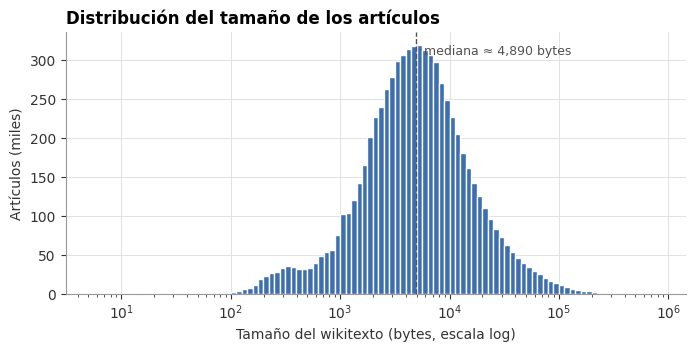

In [18]:
art_txt = paginas.filter("ns = 0 AND NOT is_redirect")
q = art_txt.select(F.percentile_approx("text_bytes", [0.1, 0.25, 0.5, 0.75, 0.9, 0.99]).alias("q")).first().q
print("Percentiles de text_bytes (p10, p25, p50, p75, p90, p99):", [f"{v:,}" for v in q])

hist = (art_txt.filter("text_bytes > 0")
        .select(F.floor(F.log10("text_bytes") * 20).alias("b"))
        .groupBy("b").count().orderBy("b").toPandas())
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.bar(10 ** (hist.b / 20), hist["count"] / 1e3, width=10 ** ((hist.b + 1) / 20) - 10 ** (hist.b / 20),
       align="edge", color=AZUL, edgecolor="#fcfcfb", linewidth=1)
ax.set_xscale("log")
ax.axvline(q[2], color="#52514e", linestyle="--", linewidth=1)
ax.text(q[2], ax.get_ylim()[1] * 0.95, f"  mediana ≈ {q[2]:,} bytes", color="#52514e", va="top", fontsize=9)
ax.set_xlabel("Tamaño del wikitexto (bytes, escala log)")
ax.set_ylabel("Artículos (miles)")
ax.set_title("Distribución del tamaño de los artículos", loc="left")
plt.show()

In [19]:
art_txt.orderBy(F.desc("text_bytes")).select("title", "text_bytes", "n_enlaces", "n_categorias").show(10, truncate=60)

+------------------------------------------------------------+----------+---------+------------+
|                                                       title|text_bytes|n_enlaces|n_categorias|
+------------------------------------------------------------+----------+---------+------------+
|                        Japanese conjugation (mizenkei base)|    792627|      233|           2|
|         List of government schools in New South Wales (A–B)|    746752|      347|           1|
|        List of The Adventures of Ozzie and Harriet episodes|    720347|      405|           1|
|                                        Japanese conjugation|    694054|      249|           2|
|                                             List of rodents|    682025|     3367|           3|
|                                         List of 2026 albums|    676424|     3281|           3|
|2024 United States House of Representatives elections in ...|    672290|      630|           3|
|                             

### 6.3 Antigüedad de la última edición

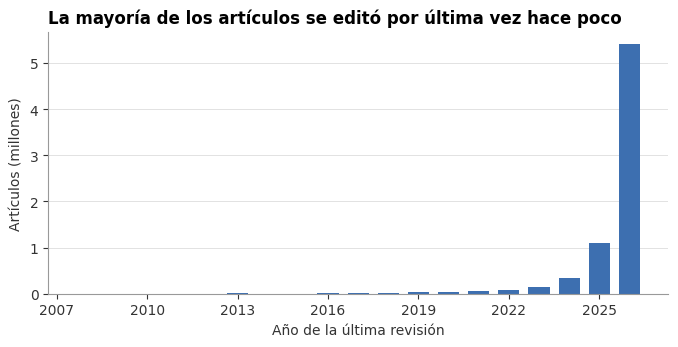

Fecha más reciente del dump: 2026-10-07 19:18:11


In [20]:
por_anio = (art_txt.groupBy(F.year("timestamp").alias("anio")).count().orderBy("anio").toPandas())
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.bar(por_anio.anio, por_anio["count"] / 1e6, color=AZUL, width=0.7)
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.set_xlabel("Año de la última revisión")
ax.set_ylabel("Artículos (millones)")
ax.set_title("La mayoría de los artículos se editó por última vez hace poco", loc="left")
ax.grid(axis="x", visible=False)
plt.show()
print("Fecha más reciente del dump:", paginas.agg(F.max("timestamp")).first()[0])

### 6.4 Modelos de contenido, editores y ediciones menores

In [21]:
spark.sql('''
    SELECT model, format, COUNT(*) AS paginas FROM paginas GROUP BY model, format ORDER BY paginas DESC
''').toPandas()

,model,format,paginas
0,wikitext,text/x-wiki,25918069
1,Scribunto,text/plain,11840
2,sanitized-css,text/css,1367
3,javascript,text/javascript,373
4,json,application/json,240
5,MassMessageListContent,application/json,162
6,css,text/css,130
7,SecurePoll,application/json,24
8,text,text/plain,10
9,worklist,application/json,4


In [22]:
spark.sql('''
    SELECT CASE WHEN contributor_user IS NOT NULL THEN 'usuario registrado'
                WHEN contributor_ip IS NOT NULL THEN 'anónimo (IP)'
                ELSE 'oculto / eliminado' END AS tipo_editor,
           COUNT(*) AS paginas,
           ROUND(100 * AVG(CAST(minor AS INT)), 1) AS pct_edicion_menor
    FROM paginas WHERE ns = 0 AND NOT is_redirect
    GROUP BY 1 ORDER BY paginas DESC
''').toPandas()

,tipo_editor,paginas,pct_edicion_menor
0,usuario registrado,7180505,49.10
1,anónimo (IP),68580,0.00
2,oculto / eliminado,14,0.00


In [23]:
# Cuentas que hicieron la última edición de más artículos (suelen ser bots de mantenimiento)
spark.sql('''
    SELECT contributor_user, COUNT(*) AS articulos FROM paginas
    WHERE ns = 0 AND NOT is_redirect AND contributor_user IS NOT NULL
    GROUP BY contributor_user ORDER BY articulos DESC LIMIT 15
''').toPandas()

,contributor_user,articulos
0,ZackBot,553643
1,Zackmann08,335853
2,Jevansen,191387
3,JJMC89 bot III,189768
4,PrimeBOT,178247
5,Staryu,170265
6,GreenC bot,157760
7,Ser Amantio di Nicolao,136716
8,PhuzBot,122609
9,InternetArchiveBot,116656


### 6.5 Enlaces y categorías por artículo

In [24]:
art_txt.select(
    F.mean("n_enlaces").alias("enlaces_medio"),
    F.percentile_approx("n_enlaces", 0.5).alias("enlaces_mediana"),
    F.max("n_enlaces").alias("enlaces_max"),
    F.mean("n_categorias").alias("categorias_medio"),
    F.sum(F.when(F.col("n_enlaces") == 0, 1).otherwise(0)).alias("sin_enlaces"),
    F.sum(F.when(F.col("n_categorias") == 0, 1).otherwise(0)).alias("sin_categorias"),
).toPandas()

,enlaces_medio,enlaces_mediana,enlaces_max,categorias_medio,sin_enlaces,sin_categorias
0,35.09,18,11987,5.87,7214,431155


In [25]:
# Categorías con más artículos (excluye categorías de mantenimiento, que suelen añadirse por plantillas)
cat_art = categorias.join(art_txt.select("page_id"), "page_id")
cat_art.groupBy("category").count().orderBy(F.desc("count")).show(20, truncate=70)

+--------------------------------------+-------+
|                              category|  count|
+--------------------------------------+-------+
|                         Living people|1149965|
| Year of birth missing (living people)| 173779|
|Place of birth missing (living people)|  66607|
|Men's association football midfielders|  65854|
|   Men's association football forwards|  49980|
|       20th-century American sportsmen|  47899|
|  Men's association football defenders|  46649|
|   Taxonomy articles created by Polbot|  31894|
|       English Football League players|  31142|
|                 Year of birth unknown|  26048|
|             English men's footballers|  24906|
|       21st-century American sportsmen|  24140|
|        American black-and-white films|  23447|
|           Articles created by Qbugbot|  20877|
|                 Year of birth missing|  20041|
|                 Year of death missing|  19964|
|                           1988 births|  18901|
|                   

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · GRAFO</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">7. Construcción del grafo de enlaces</span></div>

Se define el grafo dirigido $G = (V, E)$:

* **Nodos $V$**: artículos (`ns = 0`, no redirección), identificados por su `page_id`.
* **Aristas $E$**: hay una arista $u \to v$ si el wikitexto de $u$ contiene un enlace `[[…]]` a $v$. Muchos enlaces
  apuntan a una **redirección** (p. ej. `[[USA]]` → *United States*), así que antes se **resuelven las
  redirecciones**: el título de la redirección se reemplaza por el artículo destino. Se eliminan duplicados y
  autolazos, y los enlaces a páginas que no existen ("enlaces rojos") se descartan.

In [26]:
nodos_base = paginas.filter("ns = 0 AND NOT is_redirect").select(
    F.col("page_id").alias("id"), "title", "is_disambig")

# Redirecciones de ns 0 -> artículo destino (un salto)
redirs = paginas.filter("ns = 0 AND is_redirect").select(
    F.col("title").alias("r_title"), F.col("redirect_target").alias("target"))
redirs_ok = redirs.join(nodos_base.select(F.col("title").alias("target"), "id"), "target")
n_redirs, n_redirs_ok = redirs.count(), redirs_ok.count()
print(f"Redirecciones resueltas a un artículo: {n_redirs_ok:,} de {n_redirs:,} ({100 * n_redirs_ok / n_redirs:.1f} %)")

# Tabla título -> id de artículo (títulos de artículos + títulos de redirecciones)
titulo_a_id = nodos_base.select("title", "id").unionByName(
    redirs_ok.select(F.col("r_title").alias("title"), "id"))

aristas = (enlaces.join(titulo_a_id, enlaces.dst_title == titulo_a_id.title)
           .select(F.col("src_id").alias("src"), F.col("id").alias("dst"))
           .filter("src <> dst")
           .distinct())

t0 = time.time()
aristas.write.mode("overwrite").parquet(str(GRAFO / "aristas"))
print(f"Aristas escritas en {time.time() - t0:,.0f} s")

Redirecciones resueltas a un artículo: 12,037,636 de 12,065,403 (99.8 %)


Aristas escritas en 105 s


Dos datos sobre la resolución:

* Casi todas las redirecciones que no se resuelven apuntan **fuera de los artículos** (p. ej. `Wikify` →
  `Wikipedia:Glossary`). Las dobles redirecciones son muy pocas porque los bots las corrigen.
* Hay **un título con dos `page_id`** (*200th Division*), probablemente una página que se estaba moviendo o fusionando
  cuando se generó el dump. Los enlaces y la redirección hacia ese título cuentan para los dos nodos. Por eso el
  conteo de redirecciones resueltas sale 2 por encima de las redirecciones distintas. El efecto es despreciable.

Se calculan los grados de entrada y de salida, y se asigna a cada nodo un índice denso `idx` ∈ [0, N). Así quedan
disponibles también representaciones matriciales del grafo. Los grados se guardan con los nodos porque PageRank los
necesita para repartir el rango.

In [27]:
aristas = spark.read.parquet(str(GRAFO / "aristas"))   # se relee para cortar el linaje

# Redirecciones que no llegan a un artículo, por motivo
titulos_art = nodos_base.select(F.col("title").alias("target"))
no_resueltas = redirs.join(titulos_art, "target", "left_anti")
motivo = (no_resueltas
          .join(redirs.select(F.col("r_title").alias("target")).distinct().withColumn("es_redir", F.lit(True)), "target", "left")
          .select(F.when(F.col("es_redir"), "doble redirección (el destino es otra redirección)")
                   .when(F.col("target").rlike(r"^(Wikipedia|Category|Template|Portal|Help|Draft|File|MOS|Module|User|Special|Talk|MediaWiki|TimedText|Event)( talk)?:"),
                         "destino en otro namespace")
                   .otherwise("destino inexistente").alias("motivo")))
display(motivo.groupBy("motivo").count().orderBy(F.desc("count")).toPandas())

# Títulos de artículo repetidos (dos page_id con el mismo título)
display(nodos_base.groupBy("title").agg(F.collect_list("id").alias("ids"), F.count("*").alias("n"))
        .filter("n > 1").toPandas())

g_sal = aristas.groupBy(F.col("src").alias("id")).agg(F.count("*").alias("grado_salida"))
g_ent = aristas.groupBy(F.col("dst").alias("id")).agg(F.count("*").alias("grado_entrada"))

nodos_sin_idx = (nodos_base.join(g_sal, "id", "left").join(g_ent, "id", "left")
                 .fillna(0, ["grado_salida", "grado_entrada"]))
idx = nodos_sin_idx.select("id").rdd.map(lambda r: r[0]).sortBy(lambda x: x).zipWithIndex().toDF(["id", "idx"])
nodos = nodos_sin_idx.join(idx, "id").select("id", "idx", "title", "is_disambig", "grado_salida", "grado_entrada")
nodos.write.mode("overwrite").parquet(str(GRAFO / "nodos"))
nodos = spark.read.parquet(str(GRAFO / "nodos"))
nodos.printSchema()

,motivo,count
0,destino en otro namespace,27564
1,doble redirección (el destino es otra redirección),155
2,destino inexistente,50


,title,ids,n
0,200th Division,"[84438847, 3402359]",2


root
 |-- id: long (nullable = true)
 |-- idx: long (nullable = true)
 |-- title: string (nullable = true)
 |-- is_disambig: boolean (nullable = true)
 |-- grado_salida: long (nullable = true)
 |-- grado_entrada: long (nullable = true)



Para **PageRank sensible a tópico** hace falta definir un conjunto de teletransporte $S$ de páginas "del tema". Las
categorías de Wikipedia sirven para eso. Se guardan dos tablas:

* `categorias_nodo (id, category)`: a qué categorías pertenece cada artículo.
* `jerarquia_categorias (categoria, padre)`: qué categorías contienen a otras. Sale de las páginas del namespace 14 y
  sirve para expandir un tema a sus subcategorías.

In [28]:
categorias_nodo = categorias.join(nodos.select(F.col("id").alias("page_id")), "page_id") \
                            .select(F.col("page_id").alias("id"), "category")
categorias_nodo.write.mode("overwrite").parquet(str(GRAFO / "categorias_nodo"))

jerarquia = (categorias.join(paginas.filter("ns = 14").select("page_id", "title"), "page_id")
             .select(F.regexp_replace("title", "^Category:", "").alias("categoria"), F.col("category").alias("padre")))
jerarquia.write.mode("overwrite").parquet(str(GRAFO / "jerarquia_categorias"))

categorias_nodo = spark.read.parquet(str(GRAFO / "categorias_nodo"))
jerarquia = spark.read.parquet(str(GRAFO / "jerarquia_categorias"))
print(f"categorias_nodo: {categorias_nodo.count():,} filas | jerarquia_categorias: {jerarquia.count():,} filas")

categorias_nodo: 42,521,214 filas | jerarquia_categorias: 5,184,700 filas


### 7.1 Estadísticas del grafo

In [29]:
r = nodos.agg(
    F.count("*").alias("N"),
    F.sum("grado_salida").alias("E"),
    F.sum(F.when(F.col("grado_salida") == 0, 1).otherwise(0)).alias("dangling"),
    F.sum(F.when(F.col("grado_entrada") == 0, 1).otherwise(0)).alias("sin_entrada"),
    F.sum(F.when((F.col("grado_entrada") == 0) & (F.col("grado_salida") == 0), 1).otherwise(0)).alias("aislados"),
    F.max("grado_salida").alias("max_salida"),
    F.max("grado_entrada").alias("max_entrada"),
).first()
N, E = r.N, r.E
pd.Series({
    "nodos (artículos) N": f"{N:,}",
    "aristas E": f"{E:,}",
    "grado medio E/N": f"{E / N:.2f}",
    "densidad E/(N(N-1))": f"{E / (N * (N - 1)):.2e}",
    "nodos colgantes (sin salida)": f"{r.dangling:,} ({100 * r.dangling / N:.2f} %)",
    "nodos sin enlaces de entrada": f"{r.sin_entrada:,} ({100 * r.sin_entrada / N:.2f} %)",
    "nodos aislados": f"{r.aislados:,}",
    "grado de salida máximo": f"{r.max_salida:,}",
    "grado de entrada máximo": f"{r.max_entrada:,}",
}, name="valor").to_frame()

,valor
nodos (artículos) N,"7,249,099"
aristas E,"236,242,098"
grado medio E/N,32.59
densidad E/(N(N-1)),4.50e-06
nodos colgantes (sin salida),"7,634 (0.11 %)"
nodos sin enlaces de entrada,"457,439 (6.31 %)"
nodos aislados,"2,779"
grado de salida máximo,"11,197"
grado de entrada máximo,"264,884"


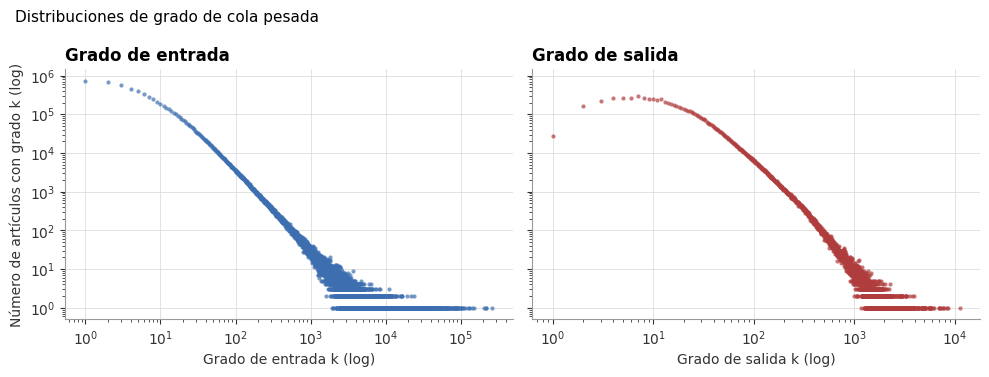

In [30]:
dist_ent = nodos.groupBy("grado_entrada").count().toPandas()
dist_sal = nodos.groupBy("grado_salida").count().toPandas()

fig, axs = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, d, col, color, nombre in ((axs[0], dist_ent, "grado_entrada", AZUL, "entrada"),
                                  (axs[1], dist_sal, "grado_salida", ROJO, "salida")):
    d = d[d[col] > 0]
    ax.scatter(d[col], d["count"], s=9, color=color, alpha=0.7, linewidths=0)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel(f"Grado de {nombre} k (log)")
    ax.set_title(f"Grado de {nombre}", loc="left")
axs[0].set_ylabel("Número de artículos con grado k (log)")
fig.suptitle("Distribuciones de grado de cola pesada", x=0.02, ha="left", fontsize=11)
plt.tight_layout()
plt.show()

En escala log-log las dos distribuciones se ven casi rectas. Eso **no basta** para hablar de una ley de potencias
$P(k) \propto k^{-\alpha}$. Una prueba sencilla es estimar $\alpha$ por máxima verosimilitud (aproximación discreta
de Clauset, Shalizi y Newman, 2009) desde distintos umbrales $k_{min}$:

$$\hat\alpha = 1 + n \Big/ \sum_{k_i \ge k_{min}} \ln \frac{k_i}{k_{min} - 1/2}.$$

Si la cola fuera una ley de potencias, $\hat\alpha$ casi no cambiaría al mover $k_{min}$.

In [31]:
grados = nodos.select("grado_entrada", "grado_salida").toPandas()
filas_alfa = []
for kmin in (10, 50, 100, 1000):
    fila = {"k_min": kmin}
    for col, nombre in (("grado_entrada", "entrada"), ("grado_salida", "salida")):
        k = grados[col].to_numpy()
        cola = k[k >= kmin]
        fila[f"α {nombre}"] = 1 + len(cola) / np.log(cola / (kmin - 0.5)).sum()
        fila[f"n {nombre}"] = len(cola)
    filas_alfa.append(fila)
display(pd.DataFrame(filas_alfa).set_index("k_min").style.format({"α entrada": "{:.2f}", "α salida": "{:.2f}",
                                                                    "n entrada": "{:,}", "n salida": "{:,}"}))
print("Moda del grado (k > 0): entrada =", grados.grado_entrada[grados.grado_entrada > 0].mode()[0],
      "| salida =", grados.grado_salida[grados.grado_salida > 0].mode()[0])

,α entrada,n entrada,α salida,n salida
k_min,,,,
10,1.88,"2,883,443",1.91,"5,203,541"
50,2.08,"681,844",2.54,"1,111,808"
100,2.13,"328,127",2.77,"403,949"
1000,2.31,"23,047",3.60,"3,524"


Moda del grado (k > 0): entrada = 1 | salida = 7


* **Grado de entrada:** $\hat\alpha$ se mantiene entre **2.1** y **2.3** a partir de $k_{min} = 50$, un valor cercano
  al ~2.1 que se ha medido para la Web. Es compatible con una ley de potencias en la cola.
* **Grado de salida:** **no** lo es. $\hat\alpha$ crece de **1.9** a **3.6** al subir $k_{min}$, la moda está en
  **7** y no en 1, y la cola cae cada vez más rápido. Se parece más a una lognormal o a una ley de potencias truncada:
  escribir un artículo con miles de enlaces tiene un costo, recibirlos no.
* Para afirmarlo formalmente haría falta la prueba de bondad de ajuste y la comparación contra la lognormal (paquete
  `powerlaw`). Aquí basta con decir **cola pesada**.

In [32]:
print("Artículos con más enlaces de entrada (autoridades por grado):")
nodos.orderBy(F.desc("grado_entrada")).select("title", "grado_entrada", "grado_salida").show(20, truncate=60)

Artículos con más enlaces de entrada (autoridades por grado):


+--------------------+-------------+------------+
|               title|grado_entrada|grado_salida|
+--------------------+-------------+------------+
|Association football|       264884|         332|
|        World War II|       221373|         956|
|       United States|       218778|        1602|
|  The New York Times|       203664|         611|
|       New York City|       149469|        1321|
|              France|       141780|        1194|
|              London|       130318|         906|
|            AllMusic|       129358|          37|
|         World War I|       118475|         682|
|        The Guardian|       112749|         637|
|             Germany|       107263|         943|
|               India|       104323|        1231|
|      United Kingdom|       101510|        1407|
|          U.S. state|       101209|         280|
|             Village|        99569|         381|
|     Catholic Church|        93981|         759|
|             YouTube|        93780|         467|


In [33]:
print("Artículos con más enlaces de salida (listas y desambiguaciones suelen dominar):")
nodos.orderBy(F.desc("grado_salida")).select("title", "grado_salida", "grado_entrada", "is_disambig").show(15, truncate=60)

Artículos con más enlaces de salida (listas y desambiguaciones suelen dominar):


+------------------------------------------------+------------+-------------+-----------+
|                                           title|grado_salida|grado_entrada|is_disambig|
+------------------------------------------------+------------+-------------+-----------+
|                    List of birds by common name|       11197|            3|      false|
|                    List of people from Illinois|        8664|            9|      false|
|                     List of least concern birds|        8343|            8|      false|
|    Alphabetical list of municipalities of Italy|        7952|            2|      false|
|            List of people with given name Peter|        7669|            3|      false|
|               List of places named after people|        7654|           46|      false|
|List of association football stadiums by country|        7363|           80|      false|
|                        List of stock characters|        7140|           54|      false|
|        I

In [34]:
# Ejemplo: vecinos de salida y de entrada de un artículo
pid = (nodos.filter(F.col("title") == "PageRank").first()
       or nodos.orderBy(F.desc("grado_entrada")).first())
t = nodos.select(F.col("id").alias("v"), F.col("title").alias("t"))
print(f"{pid.title}: id={pid.id}, idx={pid.idx}, salida={pid.grado_salida}, entrada={pid.grado_entrada}")
print("Algunos artículos a los que enlaza:",
      [x.t for x in aristas.filter(F.col("src") == pid.id).join(t, F.col("dst") == F.col("v")).limit(12).collect()])
print("Algunos artículos que lo enlazan  :",
      [x.t for x in aristas.filter(F.col("dst") == pid.id).join(t, F.col("src") == F.col("v")).limit(12).collect()])

PageRank: id=26334893, idx=2955577, salida=126, entrada=201


Algunos artículos a los que enlaza: ['SALSA algorithm', 'Matt Cutts', 'Python (programming language)', 'Héctor García-Molina', 'Google matrix', 'Expected value', 'Eugene Garfield', 'Teoma', 'Jon Kleinberg', 'HITS algorithm', 'SimRank', 'Link relation']


Algunos artículos que lo enlazan  : ['Paywall', 'SALSA algorithm', 'Matt Cutts', 'Wassily Leontief', 'NetworkX', 'Sports rating system', 'Stanford Digital Library Project', 'Outline of algorithms', 'Amy Langville', 'Chris Barton (businessman)', 'Google matrix', 'MozDex']


In [35]:
pd.Series({sub: tam_dir(GRAFO / sub) for sub in ("nodos", "aristas", "categorias_nodo", "jerarquia_categorias")},
          name="GB en disco").to_frame()

,GB en disco
nodos,0.22
aristas,2.30
categorias_nodo,0.71
jerarquia_categorias,0.12


<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · USO</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">8. Cómo usar el grafo en la práctica</span></div>

El grafo queda en `data/grafo/` y se carga en una sesión nueva sin repetir nada de lo anterior, con Spark o con
pyarrow/pandas (los notebooks 02 y 03 usan pyarrow y `scipy.sparse`):

```python
nodos   = spark.read.parquet("../data/grafo/nodos")     # id, idx, title, is_disambig, grado_salida, grado_entrada
aristas = spark.read.parquet("../data/grafo/aristas")   # src, dst   (ids de página)
categorias_nodo = spark.read.parquet("../data/grafo/categorias_nodo")          # id, category
jerarquia       = spark.read.parquet("../data/grafo/jerarquia_categorias")     # categoria, padre
```

Qué necesita cada algoritmo:

**PageRank.** $r_j = \sum_{i \to j} \beta \, \frac{r_i}{d_i} + \frac{1-\beta}{N}$ con $\beta \approx 0.85$.
* $d_i$ = `grado_salida` (ya calculado en `nodos`).
* Los **nodos colgantes** (`grado_salida = 0`, ver sección 7.1) no reparten su rango. Hay que redistribuir su masa
  $\sum_{d_i=0} r_i$ uniformemente (o eliminarlos de forma recursiva) para que $\sum r = 1$.
* Cada iteración es un `join` de `aristas` con el vector de rangos más un `groupBy(dst)`. Conviene `cache()` para
  `aristas` y `localCheckpoint()` del vector cada pocas iteraciones, para que el linaje no crezca.

**HITS.** $a = A^\top h$, $h = A a$, normalizando en cada paso.
* $A$ es la tabla `aristas`. $A^\top h$ se calcula agrupando por `dst`, y $A a$ agrupando por `src`.
* Se puede aplicar a todo el grafo o, como en la formulación original, a un **subgrafo base**: las páginas que
  contienen un término de búsqueda (p. ej. a partir de una categoría) más sus vecinos de entrada y de salida.

**PageRank sensible a tópico.** Igual que PageRank, pero el teletransporte solo va al conjunto $S$:
$\frac{1-\beta}{|S|}$ si $j \in S$, y 0 en otro caso.
* $S$ se define con `categorias_nodo`. Por ejemplo, todos los artículos de una categoría y de sus subcategorías
  (expandidas con `jerarquia` hasta cierta profundidad):

In [36]:
# Ejemplo de construcción de un conjunto de teletransporte S (el notebook 03 lo hace para todos los temas)
tema = ["Machine learning"]
cats = spark.createDataFrame([(c,) for c in tema], ["categoria"])
for _ in range(2):   # se añaden subcategorías hasta 2 niveles
    hijas = jerarquia.join(cats.withColumnRenamed("categoria", "padre"), "padre").select("categoria")
    cats = cats.unionByName(hijas).distinct()
S = categorias_nodo.join(cats.withColumnRenamed("categoria", "category"), "category").select("id").distinct()
print(f"Categorías en el tema: {cats.count():,} | artículos en S: {S.count():,}")
S.join(nodos, "id").orderBy(F.desc("grado_entrada")).select("title", "grado_entrada").show(10, truncate=60)

Categorías en el tema: 64 | artículos en S: 1,929


+---------------------------------+-------------+
|                            title|grado_entrada|
+---------------------------------+-------------+
|                 Machine learning|         3748|
|                    Generative AI|         1103|
|Neural network (machine learning)|         1061|
|               Speech recognition|         1014|
|         R (programming language)|          946|
|             Large language model|          945|
|                    Deep learning|          940|
|                           MATLAB|          880|
|                      Time series|          778|
|        Facial recognition system|          723|
+---------------------------------+-------------+
only showing top 10 rows


<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · CIERRE</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">9. Conclusiones y limitaciones</span></div>

* El archivo es el dump `pages-articles` de la Wikipedia en inglés, con revisiones hasta el 7 de octubre de 2026:
  **25.9 millones de páginas** en 259 mil streams bz2, unos 118 GB de XML. El 74 % está en ns 0, que tiene 19.3 M
  páginas, y de esas el **62.5 % son redirecciones**. Solo quedan **7.25 M artículos** reales. Les siguen las
  categorías (2.6 M), las páginas `Wikipedia:` (1.6 M), los archivos (1.0 M) y las plantillas (0.9 M).
* El índice multistream permitió **acceso aleatorio** a cualquier artículo en milisegundos. También permitió una
  **extracción paralela exacta** (25 min con 14 procesos), verificada contra el índice, sin descomprimir el XML a disco.
* El resultado es un grafo dirigido de **7 249 099 nodos y 236 242 098 aristas** (grado medio ≈ 32.6), guardado en
  Parquet (`data/grafo/`, ~3.3 GB). Solo el 0.11 % de los nodos son colgantes y el 6.3 % no recibe enlaces. Las
  distribuciones de grado tienen cola pesada, como es típico de la Web. Los nodos con más enlaces de entrada son temas
  generales (*Association football*, *World War II*, *United States*) y fuentes muy citadas (*The New York Times*,
  *AllMusic*).

**Limitaciones a tener en cuenta al interpretar PageRank / HITS:**

* **Los enlaces que generan las plantillas no se cuentan** (navboxes, infoboxes con enlaces automáticos), porque el
  wikitexto no se expande. Sí se cuentan los enlaces escritos directamente en el artículo, que son la mayoría.
* Las redirecciones se resuelven con **un solo salto**. Las dobles redirecciones quedan sin resolver, pero son
  pocas porque los bots las corrigen.
* *200th Division* tiene dos `page_id`, así que los enlaces a ese título cuentan para los dos nodos.
* Las categorías asignadas por plantillas tampoco aparecen, y algunas categorías son de mantenimiento ("Articles
  with…", "CS1…"). Conviene filtrarlas al definir temas.
* Las páginas de desambiguación y las listas tienen grado de salida muy alto. Se pueden excluir con `is_disambig` o
  por título (`List of…`) según el análisis.

In [37]:
spark.stop()